# Lysosome dynamics: treatment x gene-perturbation joint regression (Negative_control baseline, guide count > 1)

Restricts the TrackMate track-cell population to cells that are
`Negative_control`-positive or positive for >= 1 of the 24 target genes (same
`count > 1` threshold throughout), so the regression's implicit baseline (all
24 gene indicators = 0) is an explicit, verified negative-control population
rather than "whatever's left over." One combined regression per lysosome
motility metric: `log1p(metric) ~ treatment + gene_1 + ... + gene_24 + treatment:gene_1 + ... + treatment:gene_24`.

## TrackMate track counts, by condition

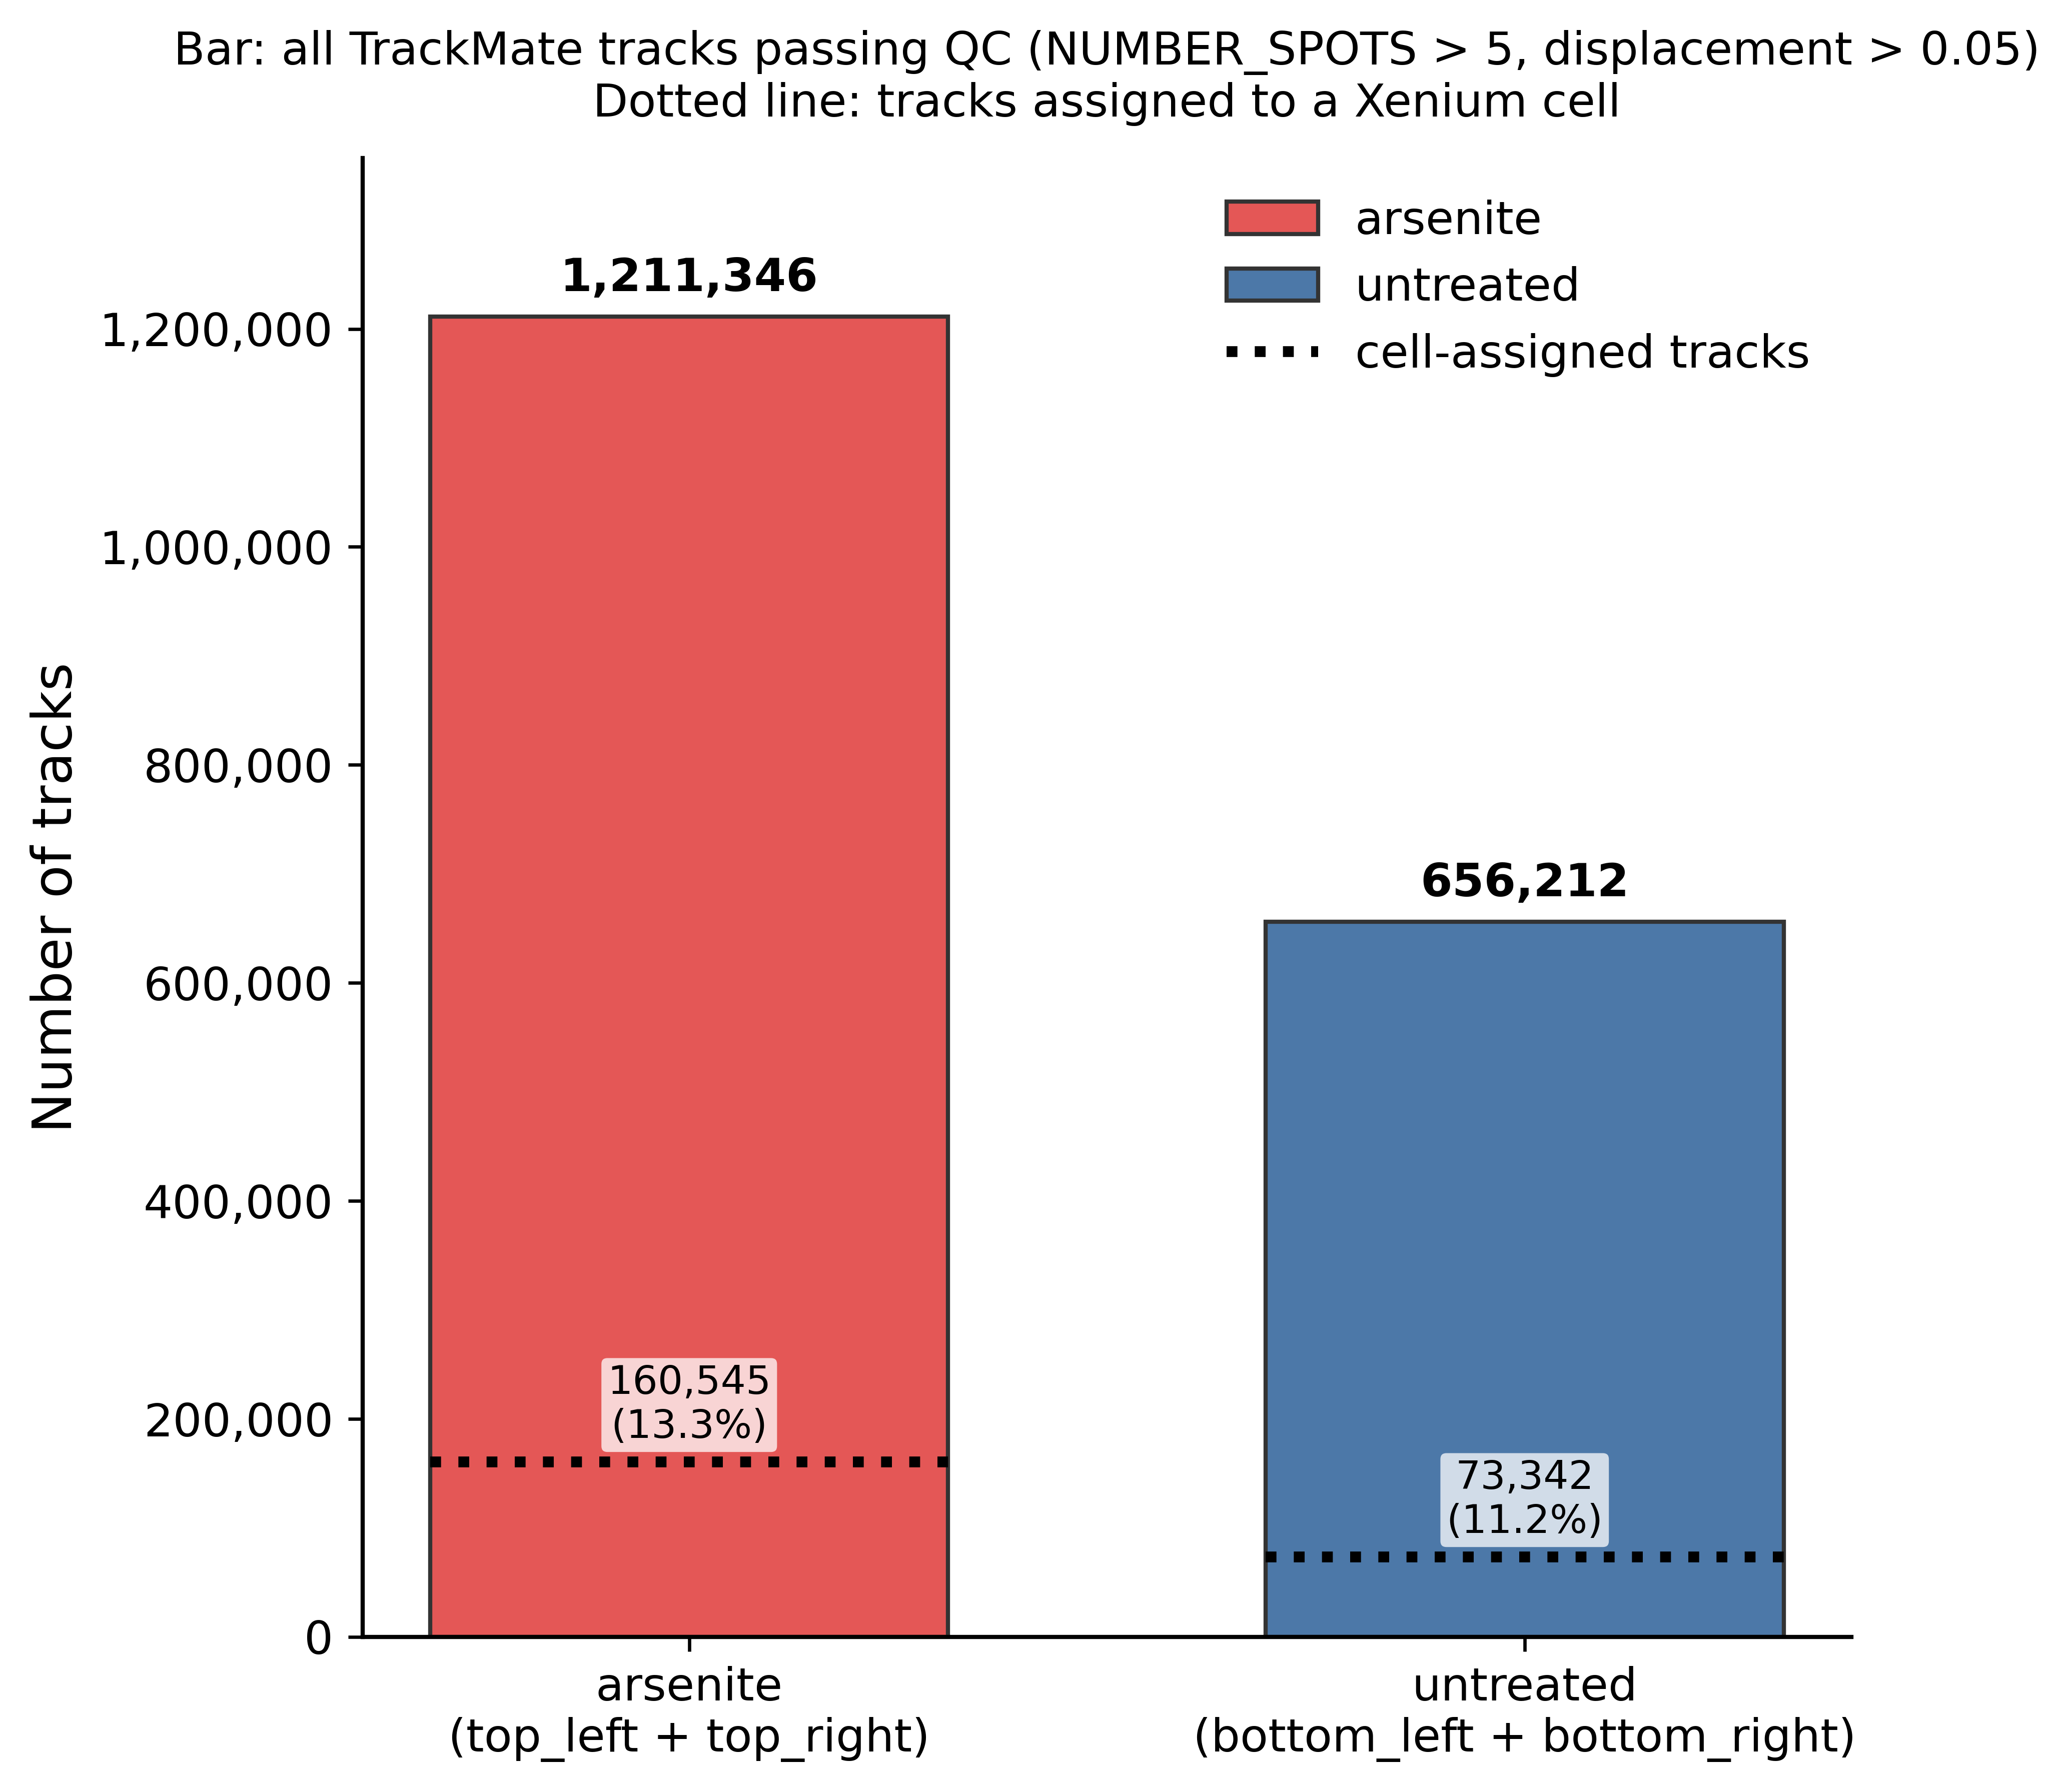

In [1]:
from IPython.display import Image
Image(filename="track_counts_per_condition.png")

## TrackMate track counts, by well

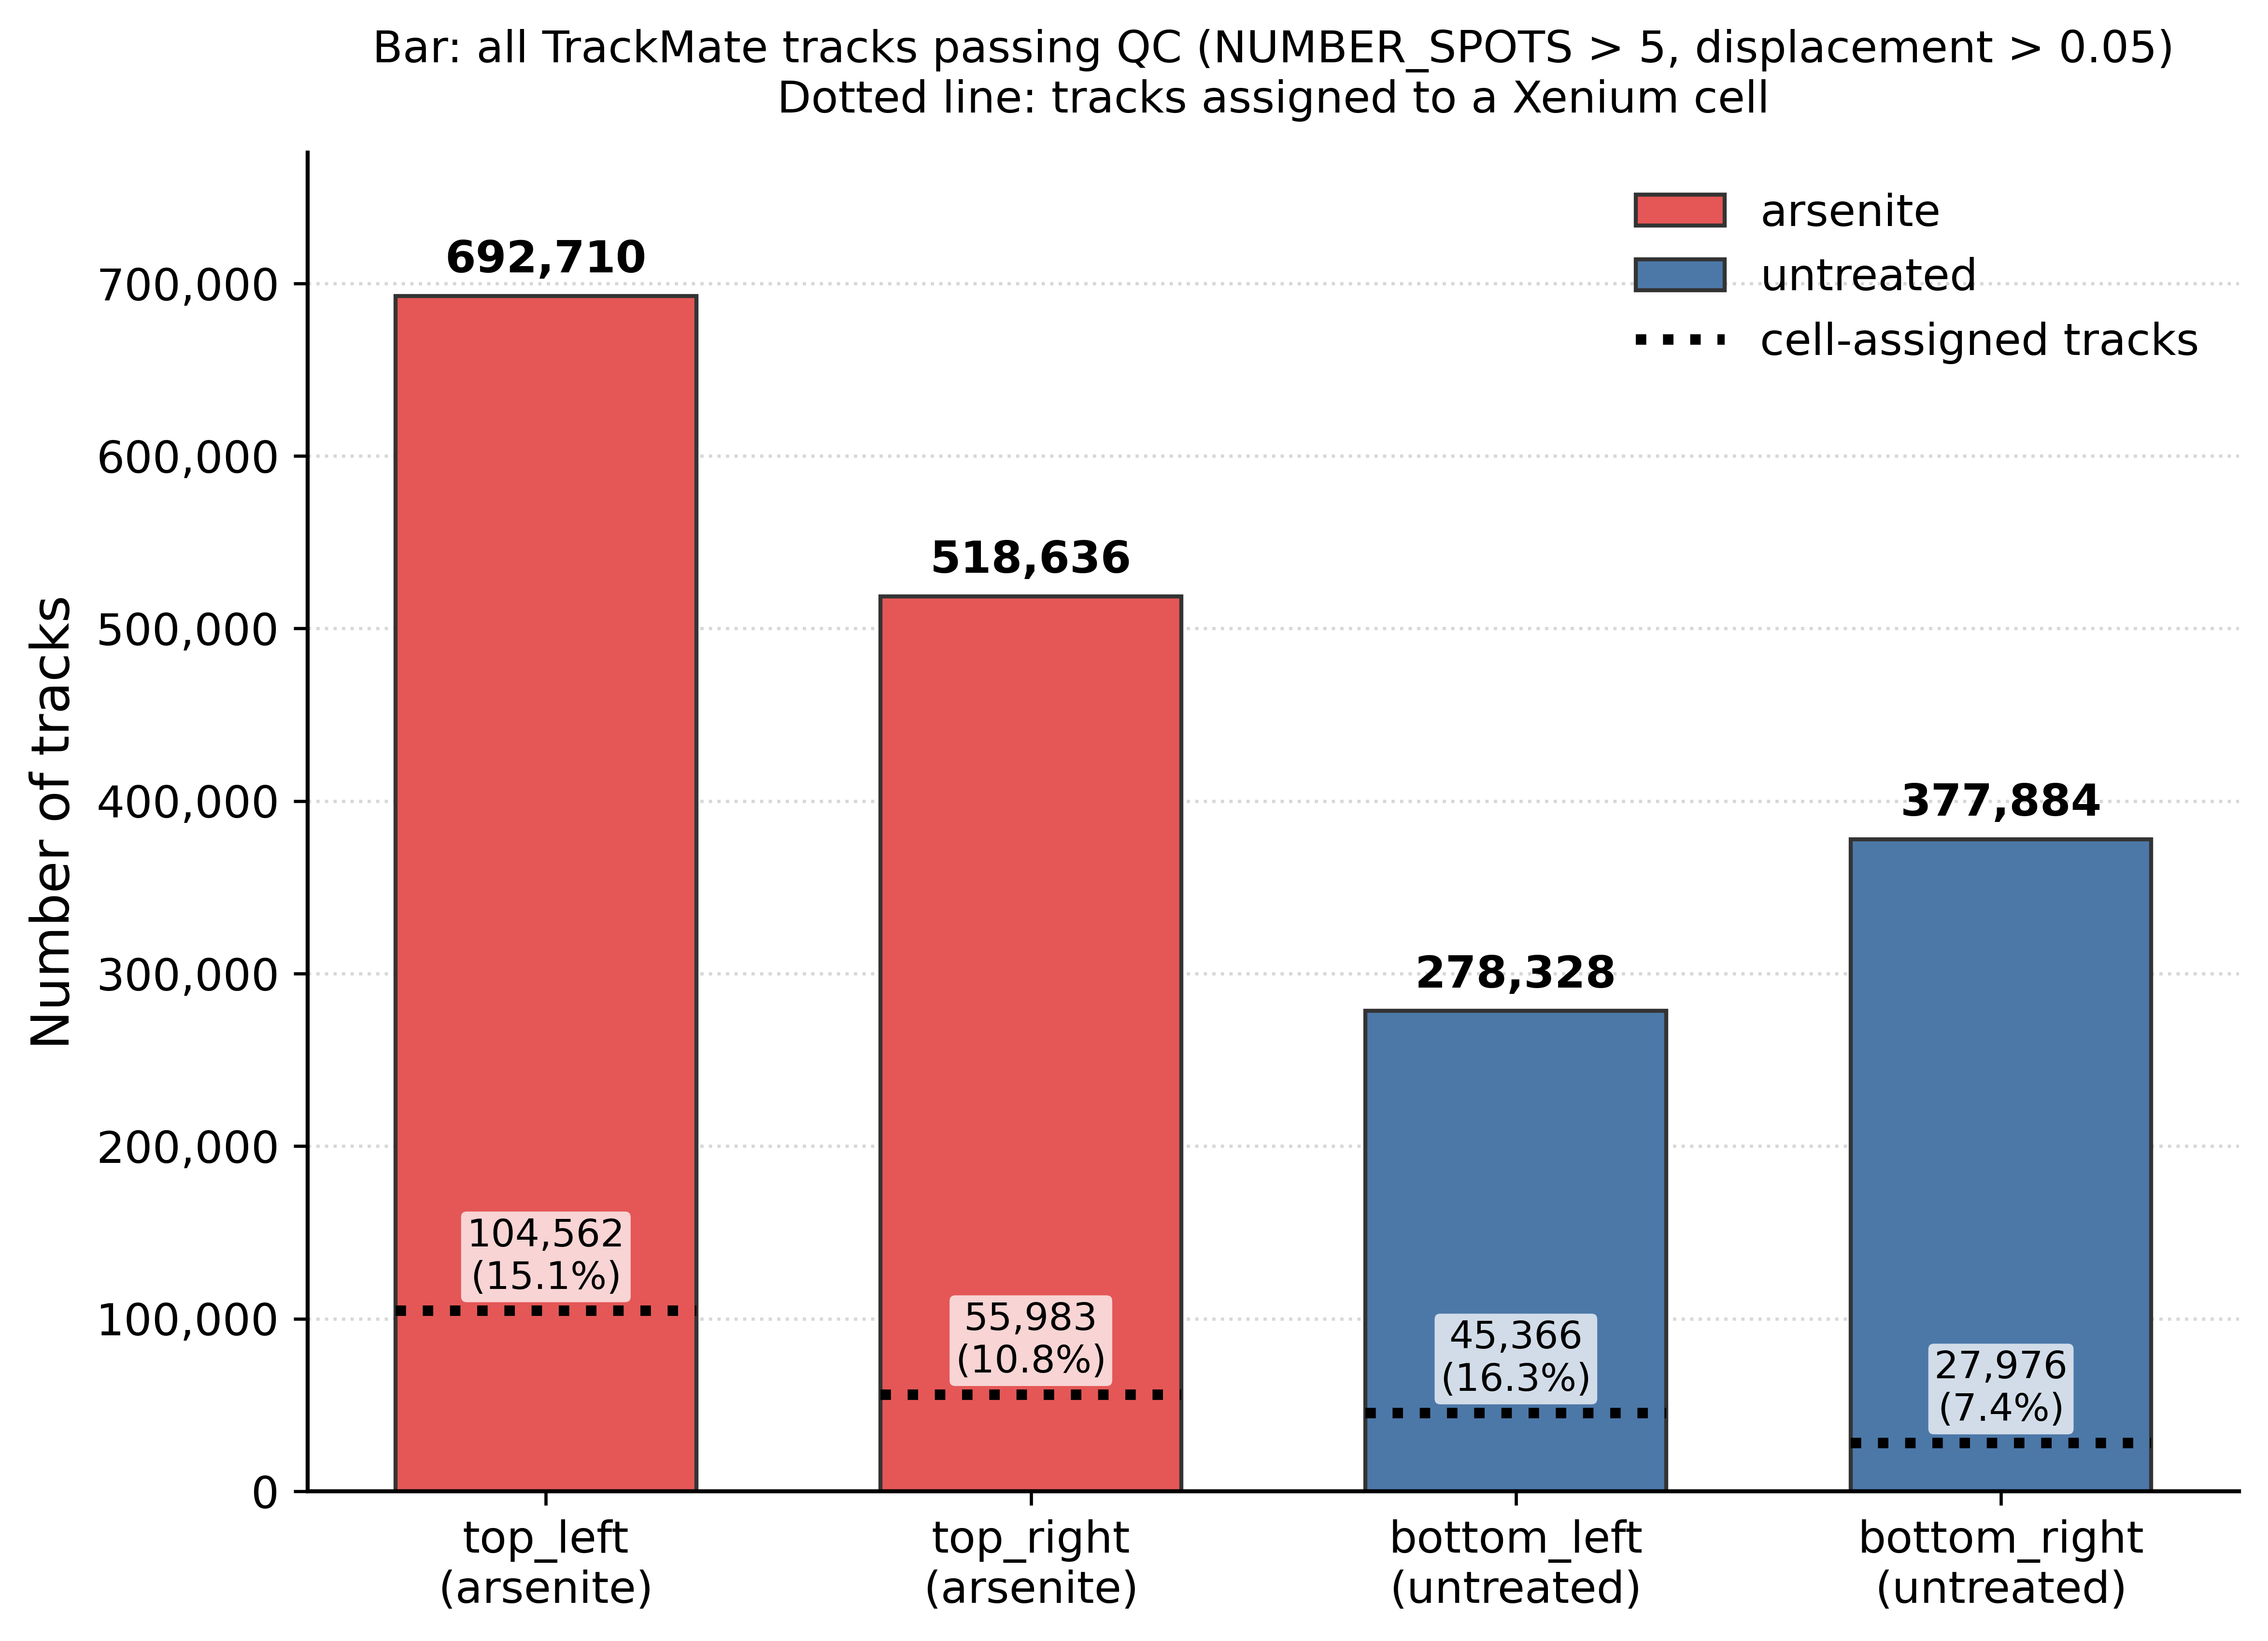

In [2]:
from IPython.display import Image
Image(filename="track_counts_per_well.png")

## Step 1 — Load TrackMate track-cell assignment and the pre-clustered h5ad

In [3]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.sparse import issparse
from statsmodels.stats.multitest import multipletests

PROJECT_DIR = "path/to/project"
TRACKCELL_OUT_DIR = "path/to/trackcell_output"
H5AD_PATH = os.path.join(PROJECT_DIR, "lyso_final_clusters.h5ad")

PIXEL_SIZE_XENIUM = 0.2125
WELL_DIRS = {
    "top_left":     "lyso_top_left",
    "top_right":    "top_right_alignment_files",
    "bottom_left":  "bottom_left",
    "bottom_right": "bottom_right_alignment_files",
}
WELL_TREATMENT = {
    "top_left": "arsenite", "top_right": "arsenite",
    "bottom_left": "untreated", "bottom_right": "untreated",
}
GRNA_COUNT_THRESHOLD = 1  # perturbed/positive if raw guide count > 1
alpha = 0.05
metrics = [
    "TRACK_MEAN_SPEED", "TRACK_DISPLACEMENT", "TOTAL_DISTANCE_TRAVELED",
    "CONFINEMENT_RATIO", "LINEARITY_OF_FORWARD_PROGRESSION", "MEAN_DIRECTIONAL_CHANGE_RATE",
]

combined = pd.read_csv(os.path.join(TRACKCELL_OUT_DIR, "combined_all_wells.csv"))
print(f"{len(combined)} track-cell rows, {combined['cell_id'].nunique()} unique cells")

adata = sc.read_h5ad(H5AD_PATH)
well_boxes = {}
for well, d in WELL_DIRS.items():
    kp = pd.read_csv(os.path.join(PROJECT_DIR, d, "keypoints.csv"))
    well_boxes[well] = (kp["fixedX"].min(), kp["fixedX"].max(), kp["fixedY"].min(), kp["fixedY"].max())
x_px = adata.obs["x_centroid"].to_numpy() / PIXEL_SIZE_XENIUM
y_px = adata.obs["y_centroid"].to_numpy() / PIXEL_SIZE_XENIUM
well_assignment = pd.Series(pd.NA, index=adata.obs_names, dtype=object)
for well, (x0, x1, y0, y1) in well_boxes.items():
    mask = (x_px >= x0) & (x_px <= x1) & (y_px >= y0) & (y_px <= y1)
    well_assignment[mask] = well
adata.obs["well"] = well_assignment
adata.obs["treatment"] = adata.obs["well"].map(WELL_TREATMENT)
adata_filtered = adata[adata.obs["well"].notna()].copy()
print(f"{adata_filtered.n_obs} / {adata.n_obs} cells overlap a BFP-imaged well")

323460 track-cell rows, 57087 unique cells


52429 / 58347 cells overlap a BFP-imaged well


## Step 2 — Off-target guide exclusion

Modified z-score on per-guide cell-detection counts, computed at the same
`count > 1` threshold used for perturbation calling below.

In [4]:
sgRNA_genes = [g for g in adata_filtered.var_names if "-" in g and "HLA" not in g]
idxs = [adata_filtered.var_names.get_loc(g) for g in sgRNA_genes]
mat_all = adata_filtered.layers["counts"][:, idxs]
if issparse(mat_all):
    mat_all = mat_all.toarray()
bin_all = (mat_all > GRNA_COUNT_THRESHOLD).astype(int)
counts_df = pd.DataFrame({"gene": sgRNA_genes, "count": bin_all.sum(axis=0)})
median_c = counts_df["count"].median()
mad = (counts_df["count"] - median_c).abs().median()
counts_df["modified_zscore"] = 0.6745 * (counts_df["count"] - median_c) / mad
MODIFIED_Z_CUTOFF = 3.5
OFF_TARGET_GENES = counts_df.loc[counts_df["modified_zscore"] > MODIFIED_Z_CUTOFF, "gene"].tolist()
print(f"Excluding as off-target (modified z > {MODIFIED_Z_CUTOFF}): {OFF_TARGET_GENES}")
remaining = [g for g in sgRNA_genes if g not in OFF_TARGET_GENES]

Excluding as off-target (modified z > 3.5): ['SOX5-3']


## Step 3 — Binary gene indicators + Negative_control indicator, restrict population

Every row with all 24 gene indicators = 0 is, by construction, a
`Negative_control`-positive cell: cells with no guide of any kind detected
above threshold are dropped entirely.

In [5]:
remaining_idxs = [adata_filtered.var_names.get_loc(g) for g in remaining]
mat_remain = adata_filtered.layers["counts"][:, remaining_idxs]
if issparse(mat_remain):
    mat_remain = mat_remain.toarray()
bin_remain = pd.DataFrame(
    (mat_remain > GRNA_COUNT_THRESHOLD).astype(int),
    index=adata_filtered.obs_names, columns=remaining,
)
gene_names = sorted({g.split("-", 1)[0] for g in remaining})
target_genes = [g for g in gene_names if g != "Negative_control"]

indicator_df = pd.DataFrame(index=bin_remain.index, columns=target_genes, dtype=int)
for gene in target_genes:
    cols = [c for c in remaining if c.startswith(gene + "-")]
    indicator_df[gene] = (bin_remain[cols] > 0).any(axis=1).astype(int)
nc_cols = [c for c in remaining if c.startswith("Negative_control-")]
indicator_df["Negative_control"] = (bin_remain[nc_cols] > 0).any(axis=1).astype(int)

df_all = combined.merge(indicator_df, left_on="cell_id", right_index=True, how="inner")
keep = (df_all["Negative_control"] == 1) | (df_all[target_genes].sum(axis=1) > 0)
n_before = len(df_all)
df_all = df_all[keep].copy()
print(f"Restricted to Negative_control-positive OR >=1-target-gene-positive cells: "
      f"{len(df_all)} / {n_before} track-cell rows kept ({df_all['cell_id'].nunique()} unique cells)")
print(df_all.groupby("treatment")["cell_id"].nunique())

df_all["treatment_arsenite"] = (df_all["treatment"] == "arsenite").astype(int)
for m in metrics:
    df_all[f"log1p_{m}"] = np.log1p(df_all[m])

Restricted to Negative_control-positive OR >=1-target-gene-positive cells: 78434 / 173112 track-cell rows kept (12200 unique cells)
treatment
arsenite     7638
untreated    4562
Name: cell_id, dtype: int64


## Step 4 — Fit one regression per metric (6 models total)

`log1p(metric) ~ treatment + gene_1 + ... + gene_24 + treatment:gene_1 + ... + treatment:gene_24`,
cluster-robust SE by `cell_id`.

In [6]:
formula_rhs = (
    "treatment_arsenite + " + " + ".join(target_genes) + " + "
    + " + ".join(f"treatment_arsenite:{g}" for g in target_genes)
)
print(f"fitting {len(metrics)} models, {len(target_genes)} genes, formula:\n  log1p(metric) ~ {formula_rhs[:90]}...")

records = []
for m in metrics:
    ycol = f"log1p_{m}"
    d = df_all[["cell_id", "treatment_arsenite", ycol] + target_genes].dropna(subset=[ycol])
    model = smf.ols(f"{ycol} ~ {formula_rhs}", data=d).fit(cov_type="cluster", cov_kwds={"groups": d["cell_id"]})
    print(f"  {m}: n={len(d)}, R^2={model.rsquared:.4f}")

    params, pvals, bse = model.params, model.pvalues, model.bse
    records.append(dict(gene=None, metric=m, term="treatment_arsenite",
                         coef=params["treatment_arsenite"], se=bse["treatment_arsenite"],
                         p=pvals["treatment_arsenite"], n=len(d)))
    for gene in target_genes:
        records.append(dict(gene=gene, metric=m, term="gene",
                             coef=params[gene], se=bse[gene], p=pvals[gene], n=len(d)))
        inter = f"treatment_arsenite:{gene}"
        records.append(dict(gene=gene, metric=m, term="interaction",
                             coef=params[inter], se=bse[inter], p=pvals[inter], n=len(d)))

reg_results = pd.DataFrame.from_records(records)
reg_results["p_adj"] = np.nan
for term, grp in reg_results.groupby("term"):
    reg_results.loc[grp.index, "p_adj"] = multipletests(grp["p"], alpha=alpha, method="fdr_bh")[1]
reg_results["significant"] = reg_results["p_adj"] < alpha
reg_results.to_csv("joint_regression_nc_baseline_thresh1_results.csv", index=False)

for term in ["treatment_arsenite", "gene", "interaction"]:
    sub = reg_results[reg_results["term"] == term]
    print(f"{term:19s}: {sub['significant'].sum()} / {len(sub)} significant (BH-adj p < {alpha})")

fitting 6 models, 24 genes, formula:
  log1p(metric) ~ treatment_arsenite + AFF1 + BCL6 + BNC2 + CARHSP1 + CREB5 + EBF1 + EBF3 + HMGB2 + ID2 + ID...


  TRACK_MEAN_SPEED: n=78434, R^2=0.0484


  TRACK_DISPLACEMENT: n=78434, R^2=0.0033


  TOTAL_DISTANCE_TRAVELED: n=78434, R^2=0.0045


  CONFINEMENT_RATIO: n=78434, R^2=0.0014


  LINEARITY_OF_FORWARD_PROGRESSION: n=78434, R^2=0.0013


  MEAN_DIRECTIONAL_CHANGE_RATE: n=78434, R^2=0.0013
treatment_arsenite : 3 / 6 significant (BH-adj p < 0.05)
gene               : 1 / 144 significant (BH-adj p < 0.05)
interaction        : 0 / 144 significant (BH-adj p < 0.05)


In [7]:
print("Significant gene main effects:")
sig_gene = reg_results[(reg_results["term"] == "gene") & reg_results["significant"]].sort_values("p_adj")
print(sig_gene[["gene", "metric", "coef", "p_adj", "n"]].round(4).to_string(index=False) if not sig_gene.empty else "  none")
print()
print("Significant treatment main effects:")
sig_treat = reg_results[(reg_results["term"] == "treatment_arsenite") & reg_results["significant"]].sort_values("p_adj")
print(sig_treat[["metric", "coef", "p_adj", "n"]].round(4).to_string(index=False) if not sig_treat.empty else "  none")
print()
print("Significant gene x treatment interactions:")
sig_inter = reg_results[(reg_results["term"] == "interaction") & reg_results["significant"]].sort_values("p_adj")
print(sig_inter[["gene", "metric", "coef", "p_adj", "n"]].round(4).to_string(index=False) if not sig_inter.empty else "  none")

Significant gene main effects:
gene             metric   coef  p_adj     n
BNC2 TRACK_DISPLACEMENT 0.0135 0.0111 78434

Significant treatment main effects:
                 metric    coef  p_adj     n
       TRACK_MEAN_SPEED -0.0065 0.0000 78434
     TRACK_DISPLACEMENT  0.0077 0.0131 78434
TOTAL_DISTANCE_TRAVELED  0.0273 0.0131 78434

Significant gene x treatment interactions:
  none


## Effect size bar plots

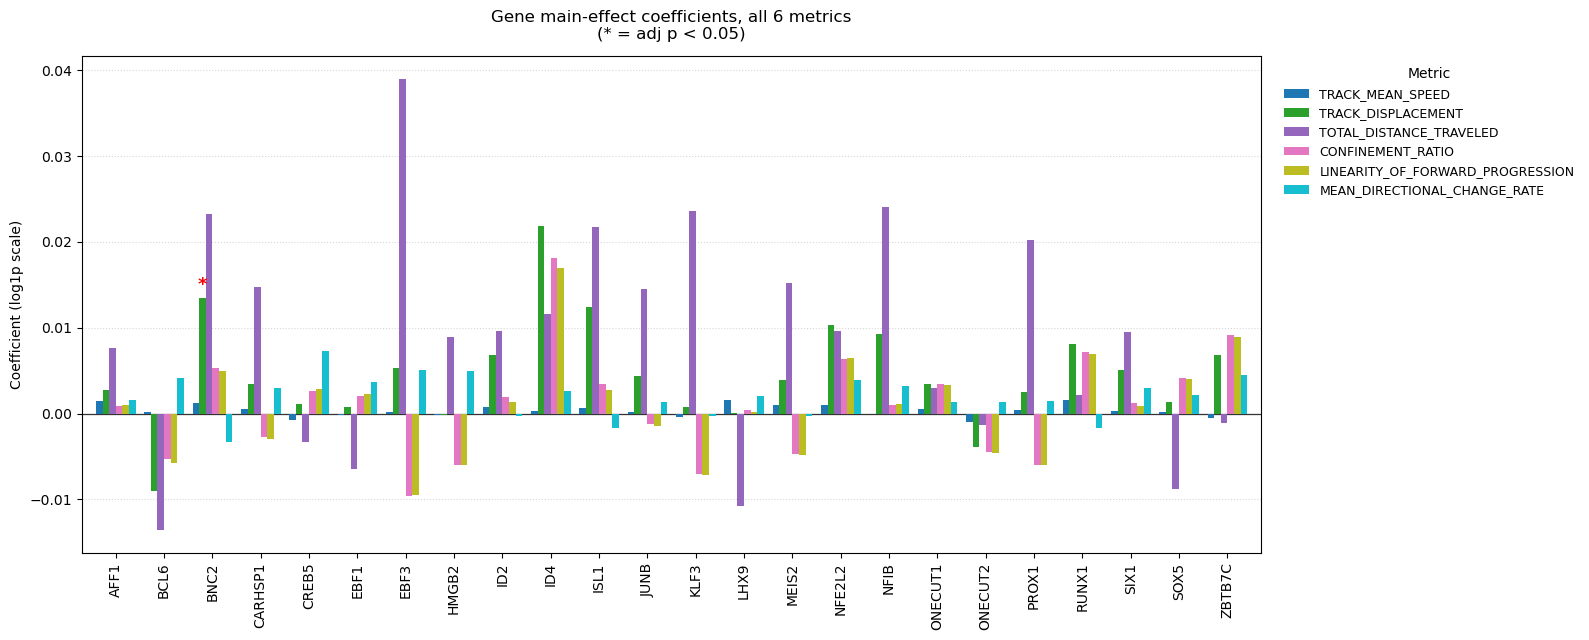

In [8]:
metrics_order = metrics
C_ARS, C_UNT = "#E45756", "#4C78A8"
metric_colors = plt.cm.tab10(np.linspace(0, 1, len(metrics_order)))
star_label = f"adj p < {alpha}"

sub_df = reg_results[reg_results["term"] == "gene"]
coef_pivot = sub_df.pivot(index="gene", columns="metric", values="coef")[metrics_order]
sig_pivot = sub_df.pivot(index="gene", columns="metric", values="significant")[metrics_order]
genes_x = coef_pivot.index.tolist()
x = np.arange(len(genes_x))
n_m = len(metrics_order)
width = 0.82 / n_m

fig, ax = plt.subplots(figsize=(16, 6.5))
for i, m in enumerate(metrics_order):
    offset = (i - (n_m - 1) / 2) * width
    vals = coef_pivot[m].values
    ax.bar(x + offset, vals, width, label=m, color=metric_colors[i], zorder=2)
    for xi, v, sig in zip(x + offset, vals, sig_pivot[m].values):
        if sig:
            ax.text(xi, v + (0.0004 if v >= 0 else -0.0004), "*", ha="center",
                    va="bottom" if v >= 0 else "top", color="red", fontsize=13, fontweight="bold")
ax.axhline(0, color="0.2", linewidth=0.9, zorder=1)
ax.set_xticks(x)
ax.set_xticklabels(genes_x, rotation=90)
ax.set_xlim(-0.7, len(genes_x) - 0.3)
ax.set_ylabel("Coefficient (log1p scale)")
ax.set_title(f"Gene main-effect coefficients, all 6 metrics\n(* = {star_label})", pad=12)
ax.legend(title="Metric", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9, frameon=False)
ax.grid(axis="y", linestyle=":", alpha=0.5, zorder=0)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("barplot_gene_thresh1.png", dpi=300, bbox_inches="tight")
plt.show()

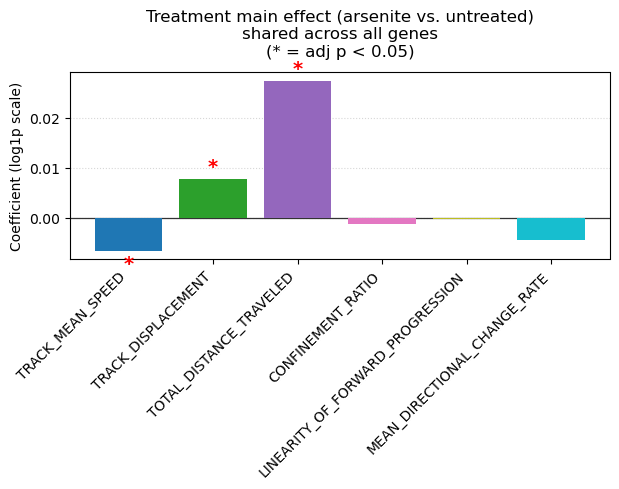

In [9]:
treat = reg_results[reg_results["term"] == "treatment_arsenite"].drop_duplicates("metric").set_index("metric").loc[metrics_order]
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.bar(metrics_order, treat["coef"].values, color=[metric_colors[i] for i in range(len(metrics_order))], zorder=2)
for xi, v, sig in zip(range(len(metrics_order)), treat["coef"].values, treat["significant"].values):
    if sig:
        ax.text(xi, v + (0.0006 if v >= 0 else -0.0006), "*", ha="center",
                va="bottom" if v >= 0 else "top", color="red", fontsize=14, fontweight="bold")
ax.axhline(0, color="0.2", linewidth=0.9, zorder=1)
ax.set_xticks(range(len(metrics_order)))
ax.set_xticklabels(metrics_order, rotation=45, ha="right")
ax.set_ylabel("Coefficient (log1p scale)")
ax.set_title(f"Treatment main effect (arsenite vs. untreated)\nshared across all genes\n(* = {star_label})", pad=12)
ax.grid(axis="y", linestyle=":", alpha=0.5, zorder=0)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("barplot_treatment_thresh1.png", dpi=300, bbox_inches="tight")
plt.show()

## Combined heatmap: treatment, gene, and gene x treatment interaction

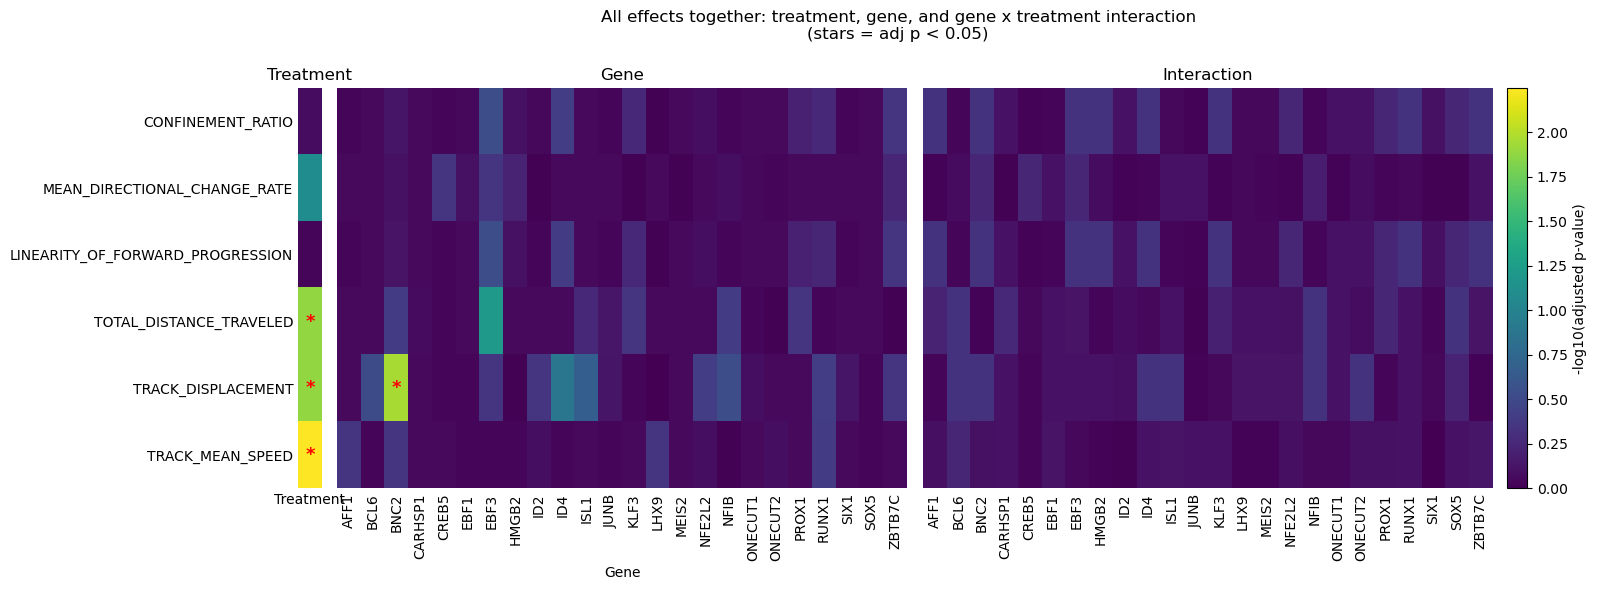

In [10]:
desired_order = [
    "CONFINEMENT_RATIO", "MEAN_DIRECTIONAL_CHANGE_RATE", "LINEARITY_OF_FORWARD_PROGRESSION",
    "TOTAL_DISTANCE_TRAVELED", "TRACK_DISPLACEMENT", "TRACK_MEAN_SPEED",
]
P_FLOOR = 1e-300
gene_heat = reg_results[reg_results["term"] == "gene"].pivot(index="metric", columns="gene", values="p_adj").loc[desired_order].clip(lower=P_FLOOR)
inter_heat = reg_results[reg_results["term"] == "interaction"].pivot(index="metric", columns="gene", values="p_adj").loc[desired_order].clip(lower=P_FLOOR)
treat_col = treat.loc[desired_order, ["p_adj"]].rename(columns={"p_adj": "Treatment"}).clip(lower=P_FLOOR)
genes_x = gene_heat.columns.tolist()
vmax = max(-np.log10(gene_heat.values.min()), -np.log10(inter_heat.values.min())) * 1.15

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharey=True,
                          gridspec_kw={"width_ratios": [1, len(genes_x), len(genes_x)], "wspace": 0.04})
panels = [("Treatment", treat_col.values, ["Treatment"]), ("Gene", gene_heat.values, genes_x),
          ("Interaction", inter_heat.values, genes_x)]
for ax, (title, mat, xlabels) in zip(axes, panels):
    im = ax.imshow(-np.log10(mat), aspect="auto", cmap="viridis", vmin=0, vmax=vmax)
    ax.set_xticks(np.arange(len(xlabels)))
    ax.set_xticklabels(xlabels, rotation=90 if len(xlabels) > 1 else 0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            if pd.notna(mat[i, j]) and mat[i, j] < alpha:
                ax.text(j, i, "*", ha="center", va="center", color="red", fontsize=13, fontweight="bold")
    ax.set_title(title, fontsize=12)
axes[0].set_yticks(np.arange(len(desired_order)))
axes[0].set_yticklabels(desired_order)
axes[1].set_xlabel("Gene")
cb = fig.colorbar(im, ax=axes, pad=0.012, fraction=0.025)
cb.set_label(f"-log10(adjusted p-value)")
fig.suptitle(f"All effects together: treatment, gene, and gene x treatment interaction\n(stars = {star_label})", y=1.03)
plt.savefig("combined_all_effects_thresh1.png", dpi=300, bbox_inches="tight")
plt.show()

## BNC2 kymographs

BNC2 is the one gene with a significant main effect in this design
(`TRACK_DISPLACEMENT`). Tracks are drawn at random from each panel's cell
population, restricted only to the same percentile range of `TRACK_DISPLACEMENT`
within the Negative_control and BNC2 groups respectively (no minimum-frame-count
cutoff) -- the same selection approach used for the kymographs in the previous
experiment.

In [11]:
import gc
from shapely.geometry import Point, Polygon

XENIUM_DIR = "path/to/xenium_output"
TRACKMATE_DIR = "path/to/trackmate_results"
FOV_SIZE = 2000
N_COLS = 18
OVERLAP = 0.11
STEP = int(round(FOV_SIZE * (1 - OVERLAP)))
MAX_CENTROID_DIST = 250  # px, drops mis-tracked/jumping spots
PCT_LOW, PCT_HIGH = 25, 75  # same percentile band applied within each status group
GENE = "BNC2"
SEED = 0

def fov_offsets(fov):
    row = (fov - 1) // N_COLS + 1
    col = (fov - 1) % N_COLS + 1
    return (col - 1) * STEP, (row - 1) * STEP

cell_boundaries_csv = pd.read_csv(
    os.path.join(XENIUM_DIR, "cell_boundaries.csv.gz"),
    usecols=["cell_id", "vertex_x", "vertex_y"],
    dtype={"cell_id": "category", "vertex_x": "float32", "vertex_y": "float32"},
)

def transform_cell_boundaries(affine_dir):
    matrix = np.loadtxt(os.path.join(PROJECT_DIR, affine_dir, "matrix.csv"), delimiter=",")
    matrix_inv = np.linalg.inv(matrix).astype(np.float32)
    x = cell_boundaries_csv["vertex_x"].to_numpy() / PIXEL_SIZE_XENIUM
    y = cell_boundaries_csv["vertex_y"].to_numpy() / PIXEL_SIZE_XENIUM
    homogeneous = np.column_stack([x, y, np.ones_like(x)])
    transformed = homogeneous.dot(matrix_inv.T)
    return pd.DataFrame({
        "cell_id": cell_boundaries_csv["cell_id"].to_numpy(),
        "x_transformed": transformed[:, 0].astype(np.float32),
        "y_transformed": transformed[:, 1].astype(np.float32),
    })

nc_ids = indicator_df.index[(indicator_df["Negative_control"] == 1) & (indicator_df[GENE] == 0)]
gene_ids = indicator_df.index[(indicator_df[GENE] == 1) & (indicator_df["Negative_control"] == 0)]

nc_band = np.percentile(combined.loc[combined["cell_id"].isin(nc_ids), "TRACK_DISPLACEMENT"].dropna(), [PCT_LOW, PCT_HIGH])
gene_band = np.percentile(combined.loc[combined["cell_id"].isin(gene_ids), "TRACK_DISPLACEMENT"].dropna(), [PCT_LOW, PCT_HIGH])
print(f"Negative_control TRACK_DISPLACEMENT [{PCT_LOW}-{PCT_HIGH}th pct]: {nc_band}")
print(f"{GENE} TRACK_DISPLACEMENT [{PCT_LOW}-{PCT_HIGH}th pct]: {gene_band}")

Negative_control TRACK_DISPLACEMENT [25-75th pct]: [0.1190545  0.26445224]
BNC2 TRACK_DISPLACEMENT [25-75th pct]: [0.12166268 0.27305477]


In [12]:
def sample_tracks(cell_ids, well_name, bdf, band, n, rng):
    sub = combined[(combined["cell_id"].isin(cell_ids)) & (combined["well"] == well_name)]
    sub = sub[(sub["TRACK_DISPLACEMENT"] >= band[0]) & (sub["TRACK_DISPLACEMENT"] <= band[1])]
    if sub.empty:
        return []
    picked = sub.sample(n=min(n, len(sub)), random_state=rng.integers(0, 2**31 - 1))

    results = []
    for fov, grp in picked.groupby("FOV"):
        x_sub, y_sub = fov_offsets(fov)
        polys, cents = {}, {}
        for cid in grp["cell_id"].unique():
            v = bdf[bdf["cell_id"] == cid]
            if len(v) < 3:
                continue
            xs = v["x_transformed"].to_numpy() - x_sub
            ys = v["y_transformed"].to_numpy() - y_sub
            poly = Polygon(zip(xs, ys))
            if not poly.is_valid:
                poly = poly.buffer(0)
            if poly.is_empty:
                continue
            polys[cid] = poly
            c = poly.centroid
            cents[cid] = np.array([c.x, c.y])

        field_str = f"{fov:04d}"
        spots_path = os.path.join(TRACKMATE_DIR, f"Field{field_str}", f"Field{field_str}_stack-spots.csv")
        spots = pd.read_csv(spots_path, header=0, skiprows=[1, 2, 3],
                             usecols=["TRACK_ID", "POSITION_X", "POSITION_Y", "FRAME"])

        for _, r in grp.iterrows():
            cid = r["cell_id"]
            if cid not in polys:
                continue
            tr = spots[spots["TRACK_ID"] == r["TRACK_ID"]].sort_values("FRAME")
            if tr.empty:
                continue
            xp = (tr["POSITION_X"].to_numpy() * 100).clip(max=FOV_SIZE - 1)
            yp = (tr["POSITION_Y"].to_numpy() * 100).clip(max=FOV_SIZE - 1)
            pts = np.column_stack([np.round(xp), np.round(yp)])
            if np.max(np.linalg.norm(pts - cents[cid], axis=1)) >= MAX_CENTROID_DIST:
                continue
            poly = polys[cid]
            d_b = np.array([poly.boundary.distance(Point(x, y)) for x, y in pts])
            inside = np.array([poly.contains(Point(x, y)) for x, y in pts])
            d_signed = np.where(inside, -d_b, d_b)
            results.append((tr["FRAME"].to_numpy(), d_signed))
        del spots
    return results


rng = np.random.default_rng(SEED)
N_PER_WELL = 10
panels = {}
for well_name, treatment in WELL_TREATMENT.items():
    bdf = transform_cell_boundaries(WELL_DIRS[well_name])
    for status, ids, band in [("Negative control", nc_ids, nc_band), (GENE, gene_ids, gene_band)]:
        got = sample_tracks(ids, well_name, bdf, band, N_PER_WELL, rng)
        panels.setdefault((status, treatment), []).extend(got)
        print(f"  {status:16s} / {treatment:9s} / {well_name:13s}: +{len(got)} tracks")
    del bdf
    gc.collect()

  Negative control / arsenite  / top_left     : +10 tracks


  BNC2             / arsenite  / top_left     : +10 tracks


  Negative control / arsenite  / top_right    : +10 tracks


  BNC2             / arsenite  / top_right    : +10 tracks


  Negative control / untreated / bottom_left  : +10 tracks


  BNC2             / untreated / bottom_left  : +10 tracks


  Negative control / untreated / bottom_right : +10 tracks


  BNC2             / untreated / bottom_right : +10 tracks


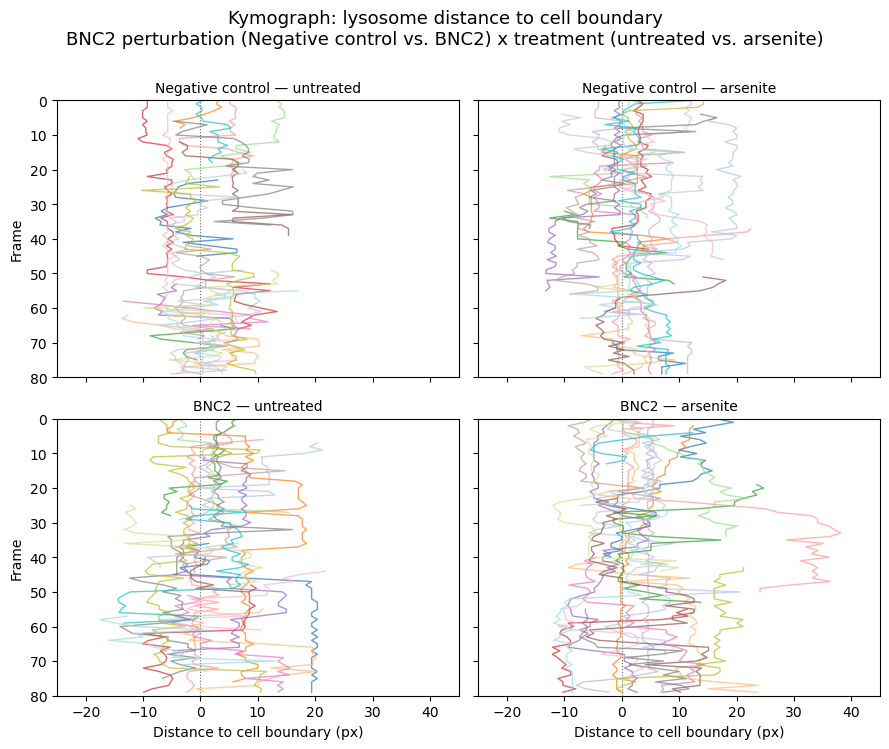

In [13]:
all_d = np.concatenate([d for tracks in panels.values() for _, d in tracks])
all_f = np.concatenate([f for tracks in panels.values() for f, _ in tracks])
xlim = (np.floor(all_d.min() / 5) * 5 - 5, np.ceil(all_d.max() / 5) * 5 + 5)
ymax = int(np.ceil(all_f.max() / 5) * 5)
colors = plt.cm.tab20.colors

fig, axes = plt.subplots(2, 2, figsize=(9, 7.6), sharex=True, sharey=True)
row_order = ["Negative control", GENE]
col_order = ["untreated", "arsenite"]
for i, status in enumerate(row_order):
    for j, treatment in enumerate(col_order):
        ax = axes[i, j]
        for k, (fr, ds) in enumerate(panels.get((status, treatment), [])):
            ax.plot(ds, fr, lw=1, alpha=0.7, color=colors[k % len(colors)], zorder=2)
        ax.set_xlim(*xlim)
        ax.set_ylim(ymax, 0)
        ax.axvline(0, color="black", lw=0.8, ls=":", alpha=0.6, zorder=0)
        ax.set_title(f"{status} — {treatment}", fontsize=10)
        if i == 1:
            ax.set_xlabel("Distance to cell boundary (px)")
        if j == 0:
            ax.set_ylabel("Frame")
fig.suptitle(f"Kymograph: lysosome distance to cell boundary\n"
             f"{GENE} perturbation ({row_order[0]} vs. {row_order[1]}) x treatment ({col_order[0]} vs. {col_order[1]})",
             fontsize=13)
fig.tight_layout()
fig.subplots_adjust(top=0.86)
plt.savefig(f"kymograph_2x2_{GENE}.png", dpi=300, bbox_inches="tight")
plt.show()

## Summary

- Restricted the TrackMate track-cell population to `Negative_control`-positive
  or >=1-target-gene-positive cells (`count > 1`), fit one joint regression per
  metric (treatment + 24 genes + 24 interactions), BH-adjusted within each term
  family.
- `BNC2` is the only gene with a significant main effect (`TRACK_DISPLACEMENT`);
  no gene x treatment interaction reaches significance.
- Kymographs sample tracks at random from each group's own `TRACK_DISPLACEMENT`
  percentile band, with no minimum track-length cutoff.